### 如何在预训练嵌入模型的基础上进一步实现嵌入模型的训练？

In [1]:

import re

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset
from torch.utils.data import random_split, DataLoader

from transformers import AutoTokenizer, AutoModelForMaskedLM

torch.manual_seed(23)

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
print("运行设备：", device)

运行设备： mps


In [3]:
# 1、加载预训练模型

pre_model_name = "bert-base-chinese"
tokenizer = AutoTokenizer.from_pretrained(pre_model_name)
# AutoModelForMaskedLM 是含 MLM 预测头，可以预测被 Mask 的 Token。
model = AutoModelForMaskedLM.from_pretrained(pre_model_name)

W1124 09:48:51.892000 8357 .venv/lib/python3.12/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-chinese
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [4]:
# 2、准备自己的语料库
corpus_path = "../../data/dl/tokenizer/sanguo.txt"
def read_corpus(corpus_path):
    with open(corpus_path, "r", encoding="utf-8") as f:
        for line in f:
            text = line.strip()

            # 跳过空行
            if not text:
                continue

            # 去除连续空白字符
            text = re.sub(r"\s+", " ", text)

            yield text

count = 0
for line in read_corpus(corpus_path):
    print(line)
    count += 1
    if count > 5 :
        break

三国演义 上卷
罗贯中
滚滚长江东逝水，浪花淘尽英雄。是非成败转头空。青山依旧在，几度夕阳红。
白发渔樵江渚上，惯看秋月春风。一壶浊酒喜相逢。古今多少事，都付笑谈中。
--调寄《临江仙》
第一回 宴桃园豪杰三结义 斩黄巾英雄首立功


In [5]:
# 3、文本清洗与 Tokenizer 编码
# 去除空文本、处理超长文本，将原始文本转换为 Token ID。
corpus_iter = read_corpus(corpus_path)
# token_ids = []
# for line in corpus_iter:
#     if line is None or line == "":
#         continue
#     line_token_ids = tokenizer(line, return_tensors="pt", truncation=True) # （BERT Base最长512个token）
#     token_ids.append(line_token_ids["input_ids"][0])
# print(len(token_ids), token_ids[0])

# 构造Dataset
class MLMDataset(Dataset):
    def __init__(self, corpus, tokenizer, max_len=128):
        self.token_ids = []
        for text in corpus:
            if line is None or line == "":
                continue
            line_token_ids = tokenizer(line, return_tensors="pt", truncation=True, max_len=max_len) # （BERT Base最长512个token）
            self.token_ids.append(line_token_ids["input_ids"][0])
    def __len__(self):
        return len(self.token_ids)
    def __getitem__(self, idx):
        return self.token_ids[idx]

dataset = MLMDataset(corpus_iter, tokenizer)
print(f"len: {len(dataset)}")

len: 1585


In [6]:
# 3.2、划分训练集与验证集, 9:1
train_size = int(0.9 * len(dataset))
valid_size = len(dataset) - train_size
train_dataset, valid_dataset = random_split(dataset, [train_size, valid_size], generator=torch.Generator().manual_seed(23))
print(len(train_dataset), len(valid_dataset))


1426 159


In [7]:
# 4、构建 MLM 训练数据
# 对输入 Token 随机执行 Mask，构建模型的训练任务。

# DataCollatorForLanguageModeling 它负责自动完成：
# 1. 将不同长度的文本 Padding 到同一长度。
# 2. 随机选择部分 Token。
# 3. 将选中的 Token 替换为 [MASK] 或其他 Token。
# 4. 创建 MLM 训练标签。

from transformers import DataCollatorForLanguageModeling
# MLM 数据处理器
data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=True,
    mlm_probability=0.15
)

# DataLoader
batch_size = 16

train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=data_collator)
valid_dataset = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False, collate_fn=data_collator)

print(len(train_dataloader), len(valid_dataset))

90 10


In [8]:
train_batch = next(iter(train_dataloader))
print(train_batch)
for key, value in train_batch.items():
    # [B, L], B 是批次大小，L是当前batch的动态padding长度
    print(key, value.shape)


{'input_ids': tensor([[  101,   103,   671,  1726,  2155,   103,  1736,   103,  3345,   676,
          5310,   721,  3168,  7942,  2353,  5739,  7413,  7674,  4989,  1216,
           102],
        [  101,  5018,   671,  1726,  2155,  3425,  1736,  6498,  3345,   676,
          5310,   721,   103,  7942,  2353,  5739,   103,  7674,  4989,  1216,
           102],
        [  101,  5018,   671,   103,  2155,  3425,  1736,  6498,  3345,   676,
          5310,   721,  3168,  7942,  2353,  5739,  7413,  7674,  4989,  1216,
           102],
        [  101,  5018,   671,  1726,  2155,  3425,  1736,  6498,  3345,   676,
          5310,   721,  3168,  7942,  2353,   103,  7413,  7674,  4989,  1216,
           102],
        [  101,  5018,   671,  1726,  2155,   103,  1736,  6498,  3345,   103,
          5310,   721,  3168,  7942,  2353,  5739,  7413,  7674,  4989,  1216,
           102],
        [  101,  5018,   671,  1726,  2155,   103,  1736,  6498,  3345,   676,
          5310,   721,  3168,   

In [9]:
# 五、第四步：使用自己的语料继续训练 BERT
# 使用 MLM Loss、AdamW 优化器更新模型参数。
model = model.to(device)
optimizer = optim.Adam(model.parameters(), lr=0.00001, weight_decay=0.01)
criterion = nn.CrossEntropyLoss()

train_losses, valid_losses = [], []

# 训练
epochs = 5
for epoch in range(epochs):
    model.train()

    train_loss_sum = 0
    train_samples = 0
    for batch in train_dataloader:
        # 将数据放入正确的设备上
        batch = {key: value.to(device) for key, value in batch.items()}

        optimizer.zero_grad(set_to_none=True)
        # 模型会自动完成：
        # 1. 获取输入 Token ID。
        # 2. 经过 BERT Transformer Encoder。
        # 3. 经过 MLM 预测头。
        # 4. 预测每个位置的 Token 概率。
        # 5. 根据 labels 计算交叉熵损失。
        # 因此，你不需要自己编写 CrossEntropyLoss。
        # 模型内部已经帮你完成了这部分工作。
        outputs = model(**batch)
        loss = outputs.loss
        loss.backward()
        optimizer.step()

        size = len(batch["input_ids"])
        train_samples += size
        train_loss_sum += loss.item() * size

    train_loss = train_loss_sum / train_samples
    train_losses.append(train_loss)

    model.eval()
    valid_loss_sum = 0
    valid_samples = 0
    with torch.no_grad():
        for batch in valid_dataset:
            batch = {key: value.to(device) for key, value in batch.items()}
            outputs = model(**batch)
            loss = outputs.loss

            size = len(batch["input_ids"])
            valid_samples += size
            valid_loss_sum += loss.item() * size

    valid_loss = valid_loss_sum / valid_samples
    valid_losses.append(valid_loss)

    print(f"epoch: {epoch}, train_loss: {train_loss}, valid_loss: {valid_loss}")




epoch: 0, train_loss: 0.3464184715592976, valid_loss: 0.01208049746423538
epoch: 1, train_loss: 0.018473574622445393, valid_loss: 0.024816745007154386
epoch: 2, train_loss: 0.003920320137766377, valid_loss: 6.27261151577223e-05
epoch: 3, train_loss: 0.006487551705894632, valid_loss: 0.001604980950288571
epoch: 4, train_loss: 0.002388243106873719, valid_loss: 0.000369400452912504


In [10]:
# 保存微调后的模型
# 保存模型权重和 Tokenizer。
save_path = "../../data/output/bert-sanguo-mlm.pth"

model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

print(f"模型已保存到：{save_path}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

模型已保存到：../../data/output/bert-sanguo-mlm.pth


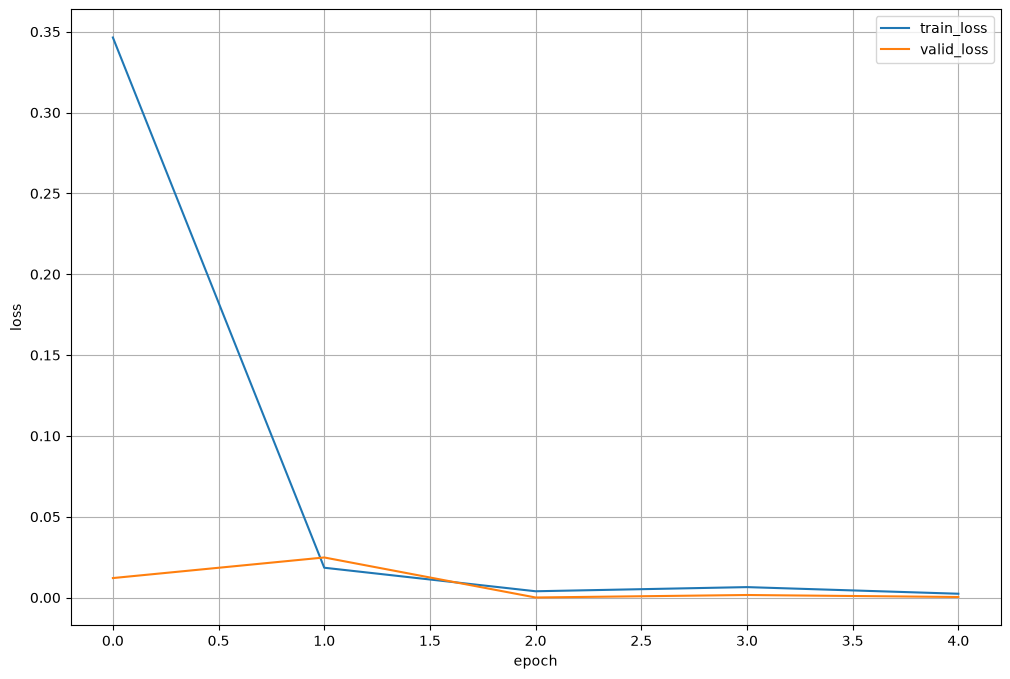

In [11]:
# 验证微调效果
# 比较训练前后的 MLM Loss，并测试模型输出。

import matplotlib.pyplot as plt
plt.figure(figsize=(12, 8))
plt.plot(train_losses, label="train_loss")
plt.plot(valid_losses, label="valid_loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.grid(True)
plt.legend()
plt.show()
